# Advanced Array Mathematics & Array Transformations

**Student:** Rani Tri Hapsari (2511017220009@mhs.ulm.ac.id)  
**Lecturer:** Rifqi Aulya Rahman (rrahman@ulm.ac.id)  
**Learning outcomes** CPMK 3. Able to process and analyze data using existing software packages.  
**Instructions:** Run the code cells in order. Read the explanations and complete the independent exercises before reading the answer key.

In [1]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


# 1. Broadcasting in NumPy  
### 1.1 Introduction to Broadcasting  
**Broadcasting** memungkinkan operasi antar-array dengan bentuk (*shape*) berbeda tanpa mengulang data secara manual. NumPy menyesuaikan dimensi yang kompatibel saat melakukan operasi **element-wise**. Contoh paling sederhana adalah menambahkan satu bilangan ke seluruh elemen array.

In [2]:
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


### 1.2 Broadcasting Rules
NumPy memeriksa ukuran setiap dimensi array dari kanan ke kiri. Dua array dapat dioperasikan jika ukuran dimensinya **sama** atau **salah satunya bernilai** 1. Jika suatu dimensi tidak ada, NumPy menganggap ukurannya 1. Jika ukuran dimensi tidak memenuhi aturan tersebut, operasi akan gagal dan muncul pesan kesalahan `ValueError`.

In [3]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


### 1.3 Shape Compatibility
Bentuk `(3, 1)` memiliki 3 baris dan 1 kolom, sedangkan `(1, 4)` memiliki 1 baris dan 4 kolom. Melalui broadcasting, NumPy secara otomatis menyesuaikan dimensi berukuran 1, sehingga menghasilkan bentuk `(3, 4)`. Fungsi `np.broadcast_shapes()` digunakan untuk memeriksa bentuk hasil sebelum operasi dilakukan.

In [4]:
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


### 1.4 Broadcasting Across Rows and Columns
Pada array 2D, kita dapat menambahkan nilai yang berbeda untuk setiap **kolom** menggunakan vektor berbentuk `(n_columns,)`. Jika ingin menambahkan nilai yang berbeda untuk setiap **baris**, gunakan `reshape(-1, 1)` untuk mengubah vektor menjadi bentuk `(n_rows, 1)`.

In [5]:
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)


**Applied example: Centering by Column Mean**

Untuk mengurangi setiap nilai data dengan **rata-rata kolomnya**, gunakan `np.mean(..., axis=0, keepdims=True)`. Hasil rata-rata berbentuk `(1, n_columns)`, sehingga melalui **broadcasting**, setiap nilai pada kolom akan dikurangi dengan rata-rata kolom tersebut.

In [6]:
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


**Common mistakes:** Array berbentuk `(3,)` tidak otomatis dianggap sebagai kolom `(3, 1)`. NumPy membandingkan ukuran dimensi dari **kanan ke kiri**. Jika ingin menggunakan nilai yang berbeda untuk setiap **baris**, ubah bentuk array menjadi `(3, 1)` menggunakan `reshape(-1, 1)`.

# 2. Saving and Loading Arrays
### 2.1 Working with `.npy` Files
File `.npy` adalah format biner NumPy untuk menyimpan **satu array** beserta informasi `shape` dan `dtype`. File ini dapat dibuka kembali tanpa mengetik ulang data. Pada contoh berikut, file dibuat di folder kerja notebook agar bisa digunakan pada bagian selanjutnya.

In [7]:
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


### 2.2 Loading Arrays (np.load)
Gunakan `np.load("nama_file.npy")` untuk membaca array yang tersimpan. File harus berada di lokasi yang sesuai dengan path yang digunakan. `allow_pickle=False` dipakai untuk membatasi pemuatan objek Python yang tidak diperlukan dalam contoh numerik ini.

In [8]:
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


### 2.3 Saving Arrays (`np.save`)
`np.save("file.npy", array)` menyimpan array NumPy ke file `.npy`. Contoh ini menyimpan data nilai ujian dalam file baru. Gunakan nama berbeda agar file yang telah dibuat sebelumnya tidak tertimpa.

In [9]:
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]


### 2.4 Inspecting Loaded Arrays
Setelah data dibuka, periksa `.shape`, `.ndim`, dan `.dtype` untuk memastikan struktur tetap sesuai. `np.array_equal()` membandingkan kesamaan nilai serta bentuk array sebelum dan setelah penyimpanan.

In [10]:
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


**Important distinction:** `.npy` mempertahankan bentuk dan tipe data array NumPy, tetapi bukan format tabel dengan nama kolom seperti CSV. Gunakan `np.load()` hanya untuk file dari sumber, terutama jika suatu saat bekerja dengan array bertipe `object`.

# 3. Image Arrays and Transformations
### 3.1 Understanding RGB and RGBA Arrays
Gambar berwarna dapat direpresentasikan sebagai array 3D dengan bentuk `(height, width, channels)`. **RGB** memiliki 3 kanal (Red, Green, Blue); **RGBA** memiliki kanal keempat, yaitu Alpha (transparansi). Pada gambar 8-bit, nilai tiap kanal biasanya berada pada rentang **0 sampai 255**.

In [11]:
# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


### 3.2 Selecting Image Color Channels
Gunakan `image[:, :, 0]` untuk kanal **Red**, indeks `1` untuk **Green**, dan indeks `2` untuk **Blue**. Setelah memilih satu kanal, hasilnya menjadi array **2D** `(height, width)`. Pemilihan `image[:, :, 0:1]` mempertahankan dimensi kanal.

In [12]:
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)


### 3.3 Manipulating Pixel Values
Nilai piksel dapat diubah dengan operasi NumPy, misalnya meningkatkan kecerahan atau mengurangi salah satu kanal. Karena `uint8` hanya menampung nilai 0–255, ubah dahulu ke tipe bilangan yang lebih besar sebelum penjumlahan, kemudian batasi hasil dengan `np.clip()` agar tidak terjadi *overflow*.

In [13]:
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]


### 3.4 Flipping Arrays (`np.flip`)
`np.flip(image, axis=0)` membalik posisi **atas–bawah** (vertikal), sedangkan `axis=1` membalik posisi **kiri–kanan** (horizontal). Pada gambar RGB, sumbu `2` adalah kanal warna, sehingga membalik `axis=2` justru mengubah urutan kanal, bukan orientasi gambar.

In [14]:
vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)

Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)


**Optional Visualization**

Kode berikut menampilkan gambar sintetis tanpa mengunduh file dari internet. Bagian ini memakai `matplotlib` sebagai bantuan visual; konsep transformasinya tetap menggunakan NumPy.

In [16]:
# Opsional untuk menampilkan gambar pada contoh Section 3:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [17]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.0


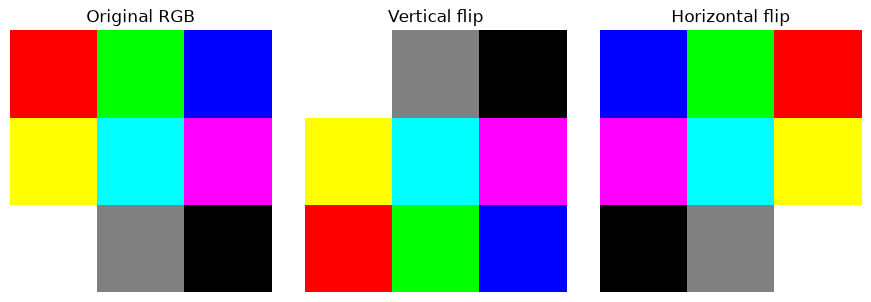

In [18]:
try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

# 4. Transposing Arrays
### 4.1 Array Transposition
**Transposition** menukar susunan sumbu array. Untuk matriks 2D, `.T` atau `np.transpose()` mengubah baris menjadi kolom dan sebaliknya: `(rows, columns)` menjadi `(columns, rows)`. Pada array 1D, `.T` tidak mengubah bentuknya.

In [19]:
data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)


### 4.2 Transposing by Axis
Untuk array 3D atau lebih, `np.transpose(array, axes=(...))` menentukan **urutan baru semua sumbu**. Misalnya, `(0, 1, 2)` menjadi `(1, 0, 2)` berarti menukar sumbu pertama dan kedua. `np.swapaxes()` dapat dipakai jika hanya dua sumbu yang ditukar.

In [20]:
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))

=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


# 5. Stacking and Splitting Arrays
### 5.1 Splitting Arrays (`np.split`)
**Splitting** digunakan untuk membagi satu array menjadi beberapa bagian. Fungsi `np.split()` membagi array dengan jumlah elemen yang **sama banyak** pada setiap bagian. Jika jumlah elemen tidak dapat dibagi rata, gunakan `np.array_split()` yang memungkinkan hasil pembagian memiliki jumlah elemen berbeda.

In [21]:
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]


Kode `np.arange(7)` membuat array berisi angka `[0, 1, 2, 3, 4, 5, 6]`. Selanjutnya, `np.array_split(..., 3)` membagi array tersebut menjadi **3 bagian** dengan jumlah elemen masing-masing **3, 2, dan 2**. Perulangan `for part in ...` mengambil setiap bagian, kemudian `part.tolist()` mengubahnya menjadi **list Python**. Terakhir, `print()` menampilkan hasil pembagian berupa `[[0, 1, 2], [3, 4], [5, 6]]`.

### 5.2 Stacking Arrays (np.stack)
**Stacking** menyatukan array yang memiliki bentuk **sama** dengan membuat **sumbu baru**. Sebagai contoh, dua vektor `(3,)` dapat menjadi `(2, 3)` jika `axis=0` atau `(3, 2)` jika `axis=1`. Berbeda dari `np.concatenate()`, `np.stack()` menambah jumlah dimensi, bisa dilihat dari dimensi/ notasi kurung sebelum di stack atau di concatenate

In [22]:
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


### 5.3 Reshaping Split Arrays
Setelah array dibagi menggunakan `np.split()`, setiap bagian dapat diubah bentuknya menggunakan `reshape()` tanpa mengubah **jumlah elemen**. Misalnya, array 2D berbentuk `(3, 2)` yang memiliki 6 elemen dapat diubah menjadi array 1D berbentuk `(6,)`. Selanjutnya, dua array 1D tersebut dapat digabungkan menggunakan `np.stack()` menjadi array 2D berbentuk `(2, 6)`.

In [23]:
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


# 6. Independent Student Exercises
Selesaikan latihan berikut menggunakan **NumPy**. Tambahkan code cell di bawah setiap latihan untuk menuliskan dan menguji jawaban.

In [26]:
# Exercise 1 — Broadcasting in NumPy

import numpy as np

# Matriks dasar
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

# 1. Tambahkan bonus per kolom menggunakan broadcasting
col_bonus = np.array([5, 3, 2])
result_col = scores + col_bonus

# 2. Tambahkan bonus per baris dengan reshape(-1, 1)
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)
result_row = scores + row_bonus

# 3. Hitung rata-rata masing-masing kolom dengan keepdims=True, lalu kurangkan dari scores
col_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - col_means

# 4. Tampilkan .shape untuk setiap array bonus dan hasil perhitungan
print("Shape col_bonus:", col_bonus.shape)
print("Shape row_bonus:", row_bonus.shape)
print("Shape col_means:", col_means.shape)
print("Shape result_col:", result_col.shape)
print("Shape result_row:", result_row.shape)
print("Shape centered_scores:", centered_scores.shape)

# Tampilkan Hasil Perhitungan
print("\n--- Hasil Perhitungan ---")
print("1. Bonus per Kolom:\n", result_col)
print("2. Bonus per Baris:\n", result_row)
print("3. Centered Scores:\n", centered_scores)

Shape col_bonus: (3,)
Shape row_bonus: (3, 1)
Shape col_means: (1, 3)
Shape result_col: (3, 3)
Shape result_row: (3, 3)
Shape centered_scores: (3, 3)

--- Hasil Perhitungan ---
1. Bonus per Kolom:
 [[75 83 92]
 [80 88 97]
 [65 73 82]]
2. Bonus per Baris:
 [[71 81 91]
 [79 89 99]
 [62 72 82]]
3. Centered Scores:
 [[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]


In [27]:
# Exercise 2 — Saving and Loading Arrays

import numpy as np

# Array dasar
temperatures = np.array([[29, 31, 30],
                         [28, 32, 33],
                         [27, 30, 31]])

# 1. Simpan array ke file week11_temperatures.npy
np.save("week11_temperatures.npy", temperatures)

# 2. Buka kembali file .npy dan simpan ke variabel baru
loaded_temperatures = np.load("week11_temperatures.npy", allow_pickle=False)

# 3. Periksa .shape, .ndim, dan .dtype dari hasil pemuatan
print("Shape:", loaded_temperatures.shape)
print("Number of dimensions (.ndim):", loaded_temperatures.ndim)
print("Data type (.dtype):", loaded_temperatures.dtype)

# 4. Periksa kesamaan array asli dan hasil pemuatan
is_same = np.array_equal(temperatures, loaded_temperatures)
print("Apakah array asli dan hasil pemuatan identik?:", is_same)

Shape: (3, 3)
Number of dimensions (.ndim): 2
Data type (.dtype): int64
Apakah array asli dan hasil pemuatan identik?: True


In [28]:
# Exercise 3 — Image Arrays and Transformations

import numpy as np

# Gambar dasar (2x2 piksel dengan 3 kanal warna RGB)
image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)

# 1. Bentuk gambar dan matriks kanal Red, Green, dan Blue
print("Bentuk gambar (shape):", image.shape)

red_channel = image[:, :, 0]
green_channel = image[:, :, 1]
blue_channel = image[:, :, 2]

print("\nKanal Red:\n", red_channel)
print("Kanal Green:\n", green_channel)
print("Kanal Blue:\n", blue_channel)

# 2. Salinan gambar dengan kanal Blue diubah menjadi 0
no_blue_image = image.copy()
no_blue_image[:, :, 2] = 0

print("\nMatriks setelah kanal Blue diubah ke 0:\n", no_blue_image)

# 3. Menambah kecerahan 30 pada semua kanal
brightened_image = np.clip(image.astype(np.int16) + 30, 0, 255).astype(np.uint8)

print("\nMatriks setelah penambahan kecerahan:\n", brightened_image)

# 4. Balik gambar secara horizontal dan vertikal, lalu periksa piksel [0, 0]
vertical_flip = np.flip(image, axis=0)
horizontal_flip = np.flip(image, axis=1)

print("\nPiksel [0, 0] setelah Vertikal Flip (axis=0):", vertical_flip[0, 0])
print("Piksel [0, 0] setelah Horizontal Flip (axis=1):", horizontal_flip[0, 0])

Bentuk gambar (shape): (2, 2, 3)

Kanal Red:
 [[255   0]
 [  0 255]]
Kanal Green:
 [[  0 255]
 [  0 255]]
Kanal Blue:
 [[  0   0]
 [255 255]]

Matriks setelah kanal Blue diubah ke 0:
 [[[255   0   0]
  [  0 255   0]]

 [[  0   0   0]
  [255 255   0]]]

Matriks setelah penambahan kecerahan:
 [[[255  30  30]
  [ 30 255  30]]

 [[ 30  30 255]
  [255 255 255]]]

Piksel [0, 0] setelah Vertikal Flip (axis=0): [  0   0 255]
Piksel [0, 0] setelah Horizontal Flip (axis=1): [  0 255   0]


In [30]:
# Exercise 4 — Transposing Arrays

import numpy as np

# Array 3D dasar (2 layer, 3 baris, 4 kolom)
arr = np.arange(24).reshape(2, 3, 4)

# 1. Periksa .shape array awal
print("1. Shape array awal:", arr.shape)

# 2. Transpose urutan sumbu menjadi (1, 0, 2)
arr_transposed = np.transpose(arr, axes=(1, 0, 2))
print("2. Shape setelah np.transpose(arr, axes=(1, 0, 2)):", arr_transposed.shape)

# 3. Swapaxes untuk menghasilkan bentuk array yang sama
arr_swapped = np.swapaxes(arr, 0, 1)
print("3. Shape setelah np.swapaxes(arr, 0, 1):", arr_swapped.shape)
print("   Apakah hasil transpose dan swapaxes identik?:", np.array_equal(arr_transposed, arr_swapped))

# 4. HWC ke CHW lalu kembali ke HWC
image = np.zeros((4, 5, 3))
print("\n4a. Shape gambar awal (HWC):", image.shape)

# Ubah HWC (Height=0, Width=1, Channel=2) -> CHW (Channel=2, Height=0, Width=1)
image_chw = np.transpose(image, axes=(2, 0, 1))
print("4b. Shape setelah diubah ke CHW (2, 0, 1):", image_chw.shape)

# Kembalikan CHW (Channel=0, Height=1, Width=2) -> HWC (Height=1, Width=2, Channel=0)
image_hwc_back = np.transpose(image_chw, axes=(1, 2, 0))
print("4c. Shape setelah dikembalikan ke HWC (1, 2, 0):", image_hwc_back.shape)

1. Shape array awal: (2, 3, 4)
2. Shape setelah np.transpose(arr, axes=(1, 0, 2)): (3, 2, 4)
3. Shape setelah np.swapaxes(arr, 0, 1): (3, 2, 4)
   Apakah hasil transpose dan swapaxes identik?: True

4a. Shape gambar awal (HWC): (4, 5, 3)
4b. Shape setelah diubah ke CHW (2, 0, 1): (3, 4, 5)
4c. Shape setelah dikembalikan ke HWC (1, 2, 0): (4, 5, 3)


In [32]:
# Exercise 5 — Stacking and Splitting Arrays

import numpy as np

# Matriks dasar (3 baris, 4 kolom)
data = np.arange(1, 13).reshape(3, 4)

# 1. Membagi data menjadi dua bagian menurut kolom (axis=1) menggunakan np.split()
part1, part2 = np.split(data, 2, axis=1)

# 2. Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan reshape(-1)
print("Shape part1:", part1.shape)
print("Shape part2:", part2.shape)

vec1 = part1.reshape(-1)
vec2 = part2.reshape(-1)

print("Shape vec1 (setelah reshape):", vec1.shape)
print("Shape vec2 (setelah reshape):", vec2.shape)

# 3. Gabungkan kedua vektor memakai np.stack(axis=0) dan periksa bentuknya
stacked_result = np.stack((vec1, vec2), axis=0)

print("\nHasil stacking (axis=0):\n", stacked_result)
print("Shape hasil stacking:", stacked_result.shape)

# 4. Gunakan np.array_split() untuk membagi np.arange(10) menjadi tiga bagian
split_parts = np.array_split(np.arange(10), 3)

print("\nHasil np.array_split() pada np.arange(10):")
for idx, part in enumerate(split_parts, start=1):
    print(f"Bagian {idx}: isi = {part.tolist()}, shape = {part.shape}, jumlah elemen = {len(part)}")

Shape part1: (3, 2)
Shape part2: (3, 2)
Shape vec1 (setelah reshape): (6,)
Shape vec2 (setelah reshape): (6,)

Hasil stacking (axis=0):
 [[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
Shape hasil stacking: (2, 6)

Hasil np.array_split() pada np.arange(10):
Bagian 1: isi = [0, 1, 2, 3], shape = (4,), jumlah elemen = 4
Bagian 2: isi = [4, 5, 6], shape = (3,), jumlah elemen = 3
Bagian 3: isi = [7, 8, 9], shape = (3,), jumlah elemen = 3


In [33]:
# Exercise 6 — Integrated Statistical Practice

import numpy as np

# Data intensitas curah hujan (4 hari x 3 lokasi)
rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])

# 1. Hitung rata-rata tiap lokasi (per kolom), lalu lakukan centering via broadcasting
loc_means = np.mean(rainfall, axis=0, keepdims=True)
centered_rainfall = rainfall - loc_means

print("1. Rata-rata lokasi (shape:", loc_means.shape, "):\n", loc_means)
print("   Hasil Centering (shape:", centered_rainfall.shape, "):\n", centered_rainfall)

# 2. Simpan ke file .npy lalu muat kembali
np.save("week11_centered_rainfall.npy", centered_rainfall)
loaded_centered = np.load("week11_centered_rainfall.npy", allow_pickle=False)
print("\n2. Berhasil menyimpan dan memuat file week11_centered_rainfall.npy")

# 3. Ubah susunan dari (hari, lokasi) menjadi (lokasi, hari) dengan .T
transposed_rainfall = loaded_centered.T
print("\n3. Bentuk sebelum transpose:", loaded_centered.shape)
print("   Bentuk setelah transpose (.T):", transposed_rainfall.shape)

# 4. Bagi data hasil transposisi menjadi dua bagian menurut kolom (axis=1) dengan np.split()
part1, part2 = np.split(transposed_rainfall, 2, axis=1)
print("\n4. Shape Bagian 1 (Kolom 1-2):", part1.shape)
print("   Shape Bagian 2 (Kolom 3-4):", part2.shape)

# 5. Gabungkan kembali dengan np.concatenate(axis=1) dan buktikan kesamaannya
recombined_rainfall = np.concatenate((part1, part2), axis=1)
is_identical = np.array_equal(transposed_rainfall, recombined_rainfall)

print("\n5. Shape data setelah digabungkan kembali:", recombined_rainfall.shape)
print("   Apakah data gabungan sama dengan data sebelum dibagi?:", is_identical)

1. Rata-rata lokasi (shape: (1, 3) ):
 [[12.5  10.    6.25]]
   Hasil Centering (shape: (4, 3) ):
 [[-0.5  -2.   -1.25]
 [-2.5   5.    0.75]
 [ 7.5   1.    2.75]
 [-4.5  -4.   -2.25]]

2. Berhasil menyimpan dan memuat file week11_centered_rainfall.npy

3. Bentuk sebelum transpose: (4, 3)
   Bentuk setelah transpose (.T): (3, 4)

4. Shape Bagian 1 (Kolom 1-2): (3, 2)
   Shape Bagian 2 (Kolom 3-4): (3, 2)

5. Shape data setelah digabungkan kembali: (3, 4)
   Apakah data gabungan sama dengan data sebelum dibagi?: True


# 7. Meeting Summary and Self-Assessment
### Essential Concepts
* **Broadcasting** memungkinkan operasi antar-array dengan bentuk berbeda jika dimensi dari kanan cocok atau salah satunya 1.  
* **`reshape(-1, 1)`** membentuk vektor kolom; **`keepdims=True`** mempertahankan dimensi untuk operasi broadcasting.
* **`np.save()`** menyimpan satu array ke file **`.npy`**; **`np.load()`** membacanya kembali beserta `shape` dan `dtype`.
* **RGB** mempunyai tiga kanal dan **RGBA** empat kanal; bentuk gambar lazimnya `(height, width, channels)`.
* **`image[:, :, k]`** mengambil satu kanal warna; **`np.clip()`** membatasi nilai piksel dan mencegah hasil di luar rentang yang diinginkan.
* **`np.flip(axis=0)`** membalik atas–bawah; **`np.flip(axis=1)`** membalik kiri–kanan.
* **`.T`** mentransposisikan array; **`np.transpose(..., axes=...)`** mengatur ulang sumbu secara eksplisit, termasuk HWC → CHW.
* **`np.split()`** membagi array pada sumbu tertentu; **`np.array_split()`** dapat membagi menjadi ukuran tidak sama.
* **`np.stack()`** menambah sumbu baru, sedangkan **`np.concatenate()`** menggabungkan array pada sumbu yang sudah ada.